In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)
from imblearn.under_sampling import RandomUnderSampler

# Credit Card Fraud Analysis

Credit card fraud is still a big problem for banks and their customers. Every day, a large number of financial transactions take place across banks all over the world. The problem is that some of these transactions may be illegal operations made without the cardholder's permission. That is why it is important to understand how to distinguish normal payments from fraudulent ones.
In this project, I am working with the Credit Card Fraud Detection dataset, which is available on Kaggle. The original dataset contains information about 284,807 transactions made by European cardholders over 2 days in September 2013. Out of all these transactions, only 492 were identified as fraudulent.
The dataset contains 31 columns. Most of them (V1-V28) contain anonymised numerical values obtained using the PCA (Principal Component Analysis) method. Their original meaning is not available due to data confidentiality. There are also the Time column, which shows the time in seconds since the first transaction, Amount, which represents the payment amount and Class, which shows the type of transaction (0 - normal, 1 - fraudulent).
While working with this data, I want to find out a few things. For example, how often fraud occurs in this dataset, whether there is a difference between the amounts of normal and fraudulent transactions, and whether there are any patterns depending on the time when transactions take place. I also plan to check whether transactions with unusually large amounts may be connected to a higher risk of fraud. At the end, I also train 2 simple baseline models to see how well fraud can be detected.
Tools: Python, Pandas, Matplotlib, Scikit-learn and Imbalanced-learn.

# Data Loading and Quality Check

In [44]:
df = pd.read_csv('creditcard.csv')
print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [45]:
df.shape

(284807, 31)

In [46]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [48]:
df.isnull()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284803,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284804,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284805,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [49]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [50]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 1081


In [51]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (283726, 31)


In [52]:
df_original = pd.read_csv('creditcard.csv')
print("Fraud before removing duplicates:", df_original["Class"].sum())
print("Fraud after removing duplicates:", df["Class"].sum())

Fraud before removing duplicates: 492
Fraud after removing duplicates: 473


During the dataset check no missing values were found, but 1,081 duplicate rows were detected. The duplicates were removed, reducing the number of transactions from 284,807 to 283,726. Removing duplicates is important for further modelling because identical records could end up in both the training and testing sets. Therefore, if the cleaning had not been done, the model's performance evaluation would have been less reliable. Among the removed rows, 19 were fraudulent, so the dataset now contains 473 fraud cases instead of 492.

In [53]:
print(df["Class"].value_counts())
print ()
print(df["Class"].value_counts(normalize=True)*100)

fraud = df[df["Class"] == 1]
normal = df[df["Class"] == 0]
print("\nFraud transactions:", len(fraud))
print("Normal transactions:", len(normal))

Class
0    283253
1       473
Name: count, dtype: int64

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

Fraud transactions: 473
Normal transactions: 283253


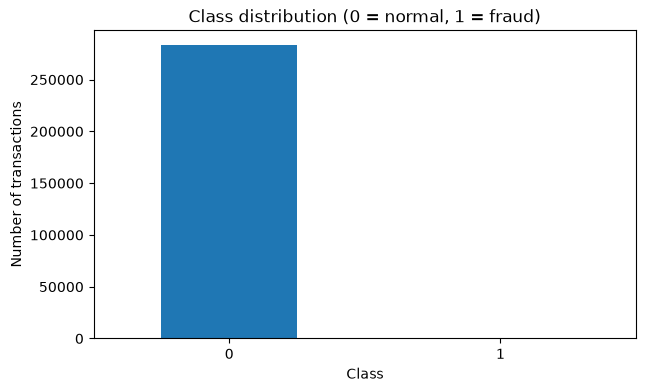

Accuracy of a model that always predicts 'normal': 0.9983


In [54]:
df["Class"].value_counts().plot(kind="bar", figsize=(7, 4))
plt.title("Class distribution (0 = normal, 1 = fraud)")
plt.xlabel("Class")
plt.ylabel("Number of transactions")
plt.xticks(rotation=0)
plt.show()

print("Accuracy of a model that always predicts 'normal':",
      round(len(normal)/len(df), 4))

After removing duplicates, the dataset contains 283,726 transactions, of which only 473 (0.167%) are fraudulent. This means that there are approximately 599 normal transactions for every fraudulent transaction. The bar chart clearly shows this imbalance: the bar representing fraudulent transactions is barely visible compared to normal transactions.
Because of this imbalance, Accuracy can be misleading. A model that always predicts a transaction as normal achieves an Accuracy of 0.9983 (99.83%), but it does not detect a single fraudulent transaction. Therefore, such a high accuracy does not reflect the actual performance of the model.
For this reason, it is also important to evaluate Recall - how many fraudulent transactions the model detects, and Precision - how many of the transactions identified as fraudulent are actually fraud. I will also use PR-AUC to evaluate the relationship between Precision and Recall.
Since there are very few fraudulent transactions in the dataset, it will be more difficult for the model to learn how to identify them. Therefore, later I will use undersampling to check how reducing the class imbalance affects the model's results.

# Transaction Amount Analysis

In [55]:
df.groupby("Class")["Amount"].agg(["count", "mean", "median", "min", "max"])

,count,mean,median,min,max
Class,,,,,
0,283253,88.413575,22.00,0.0,25691.16
1,473,123.871860,9.82,0.0,2125.87


In [56]:
print("Zero-amount transactions (all):", (df["Amount"] == 0).sum())
print("Zero-amount transactions (fraud):", fraud["Amount"].eq(0).sum())

Zero-amount transactions (all): 1808
Zero-amount transactions (fraud): 25


The table shows differences between the amounts of normal and fraudulent transactions. The average amount of fraudulent transactions is 123.87, compared to 88.41 for normal transactions. However, the median amount of fraudulent transactions is much lower: 9.82 compared to 22.00 for normal transactions. This means that a typical fraudulent transaction has a lower amount, but a few transactions with higher amounts may increase the average. The maximum amount of a normal transaction (25,691.16) is also much higher than the maximum fraudulent transaction (2,125.87).
Separately, 1,808 transactions with a zero amount were identified, of which 25 were fraudulent. This represents approximately 5.3% of all fraudulent transactions, while the fraud rate among zero-amount transactions is around 1.4%. This is approximately 8 times higher than the overall fraud rate in the dataset (0.167%), making these transactions an interesting signal for further investigation. So, the transaction amount alone is not enough to identify fraud.

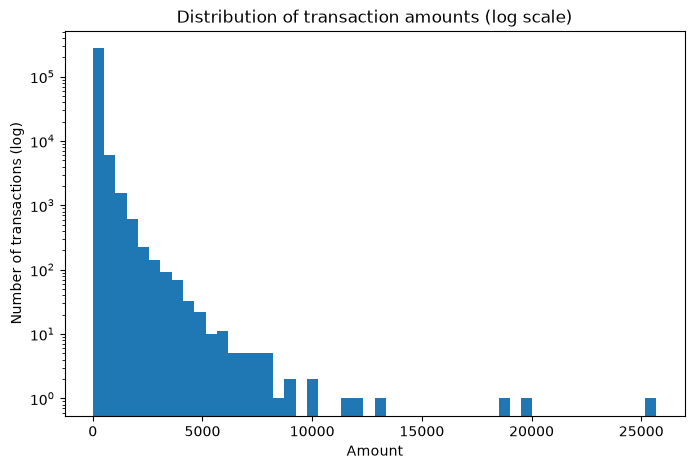

In [57]:
plt.figure(figsize=(8, 5))
plt.hist(df["Amount"], bins=50)
plt.yscale("log")
plt.title("Distribution of transaction amounts (log scale)")
plt.xlabel("Amount")
plt.ylabel("Number of transactions (log)")
plt.show()

In [58]:
small = df[df["Amount"] < 500]
print("Transactions below 500:", len(small))
print("Share of all transactions (%):", round(len(small) / len(df)*100, 1))

Transactions below 500: 274267
Share of all transactions (%): 96.7


The histogram shows that most transactions have small amounts, mainly below 500. As the transaction amount increases, the number of transactions quickly decreases, and large amounts are rare. A logarithmic scale is used to show this distribution because without it, individual transactions with large amounts would be difficult to see compared to the large number of small transactions.
However, the graph includes all transactions, so because normal transactions make up the majority of the dataset, it mainly shows their distribution rather than the distribution of fraudulent transactions separately.

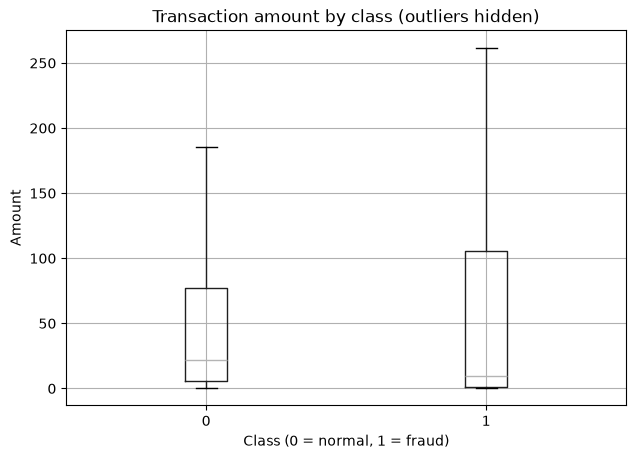

In [59]:
df.boxplot(column="Amount", by="Class", showfliers=False, figsize=(7, 5))
plt.suptitle("")
plt.title("Transaction amount by class (outliers hidden)")
plt.xlabel("Class (0 = normal, 1 = fraud)")
plt.ylabel("Amount")
plt.show()

In [60]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


Boxplot shows that the middle 50% of fraudulent transactions range from 1.00 to 105.89, while for normal transactions the range is from 5.67 to 77.46. This indicates a wider spread of amounts among fraudulent transactions. Also, 25% of fraudulent transactions have an amount of 1.00 or less. The boxes overlap, which shows that transaction amounts alone cannot clearly distinguish fraudulent transactions from normal ones.

In [61]:
threshold = df["Amount"].quantile(0.99)
big = df[df["Amount"] > threshold]

print("Threshold (top 1% of amounts):", round(threshold, 2))
print("Fraud rate among the largest transactions (%):", round(big["Class"].mean()*100, 3))
print("Fraud rate overall (%):", round(df["Class"].mean()*100, 3))
print("Number of largest transactions:", len(big))
print("Of which fraudulent:", big["Class"].sum())

Threshold (top 1% of amounts): 1018.96
Fraud rate among the largest transactions (%): 0.317
Fraud rate overall (%): 0.167
Number of largest transactions: 2838
Of which fraudulent: 9


In [62]:
print("Share of all fraud above the threshold (%):", round(big["Class"].sum()/len(fraud)*100, 1))

Share of all fraud above the threshold (%): 1.9


To check whether large transactions are more likely to be fraudulent, I selected the top 1% of transactions with the highest amounts, using 1,018.96 as the threshold. This group contains 2,838 transactions, of which only 9 are fraudulent.
The fraud rate in this group is 0.317%, compared to 0.167% in the whole dataset. This means that the fraud rate among the largest transactions is almost twice as high. However, these 9 cases represent only about 1.9% of all fraudulent transactions. This means that most fraudulent transactions have amounts below the selected threshold. Large amounts may indicate a slightly higher risk, but they are not a reliable indicator of fraud on their own.

# Transaction Activity Over Time

In [63]:
df["Hour"] = (df["Time"]/3600).astype(int)
print("Dataset covers (hours):", df["Hour"].max()+1)

Dataset covers (hours): 48


In [64]:
transactions_per_hour = df.groupby("Hour")["Class"].count()
fraud_rate_per_hour = df.groupby("Hour")["Class"].mean()*100

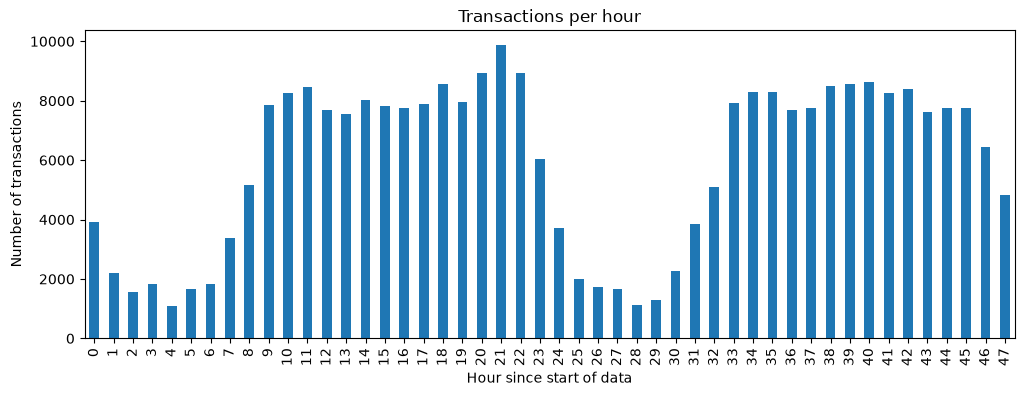

In [65]:
transactions_per_hour.plot(kind="bar", figsize=(12, 4))
plt.title("Transactions per hour")
plt.xlabel("Hour since start of data")
plt.ylabel("Number of transactions")
plt.show()

In [66]:
print("Busiest hour:", transactions_per_hour.idxmax(), "with", transactions_per_hour.max(), "transactions")
print("Quietest hour:", transactions_per_hour.idxmin(), "with", transactions_per_hour.min(), "transactions")

Busiest hour: 21 with 9875 transactions
Quietest hour: 4 with 1082 transactions


The chart shows a clear daily pattern that repeats on both days. The lowest number of transactions was at hour 4 (1,082), while the highest was at hour 21 (9,875). On both days, activity is low at first, then increases quickly and stays at a high level for most of the day. This suggests a daily activity cycle. However, the exact time of day cannot be determined because Time is measured from the first transaction in the dataset (not from midnight).

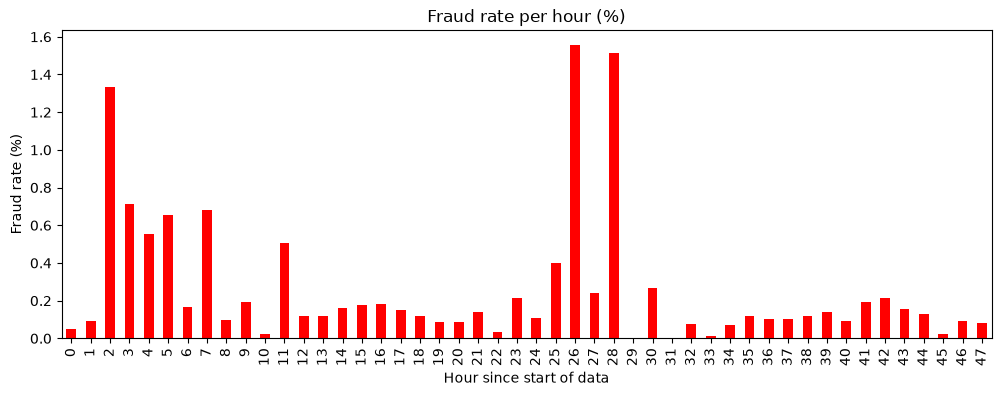

In [67]:
fraud_rate_per_hour.plot(kind="bar", figsize=(12, 4), color="red")
plt.title("Fraud rate per hour (%)")
plt.xlabel("Hour since start of data")
plt.ylabel("Fraud rate (%)")
plt.show()

In [68]:
fraud_per_hour = df.groupby("Hour")["Class"].sum()
print(fraud_per_hour.sort_values(ascending=False).head(5))

Hour
11    43
26    27
7     23
2     21
42    18
Name: Class, dtype: int64


In [69]:
print(fraud_rate_per_hour.sort_values(ascending=False).head(5))

Hour
26    1.556196
28    1.515152
2     1.335029
3     0.715072
7     0.683304
Name: Class, dtype: float64


The fraud rate varies considerably across different hours. It is highest at hour 26 (1.56%), followed by hour 28 (1.52%) and hour 2 (1.34%). These rates are about 8–9 times higher than the overall fraud rate (0.167%). Most of these hours also have lower transaction activity. However, this does not mean that fraud only occurs during periods of low activity. For example, hour 11 has the highest number of fraudulent transactions (43). Since the dataset covers only two days, these patterns should be treated as observations rather than reliable predictions.

# Correlation Analysis

In [70]:
corr_with_class = df.corr()["Class"].sort_values()
print(corr_with_class.head(5))
print(corr_with_class.tail(6))

V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dtype: float64
V8       0.033068
V19      0.033631
V2       0.084624
V4       0.129326
V11      0.149067
Class    1.000000
Name: Class, dtype: float64


In [71]:
print(corr_with_class[["Time", "Amount", "Hour"]])

Time     -0.012359
Amount    0.005777
Hour     -0.012371
Name: Class, dtype: float64


The correlation analysis shows that V17, V14 and V12 have the strongest relationships with the Class variable. These are negative correlations, meaning that higher values of these features are more often associated with normal rather than fraudulent transactions. However, even the strongest correlation is only moderate, so no single feature can clearly distinguish fraud from normal transactions.
In comparison, Time, Hour and Amount have correlations close to zero (-0.012, -0.012 and 0.006). But this does not mean that these variables are not useful. For example, the previous analysis showed differences in fraud rates across hours, but this pattern is not linear, so correlation does not capture it.
Also, V1-V28 are anonymised features, so their exact meaning cannot be explained. Correlation only shows linear relationships and does not prove causation. Since no single feature is sufficient, the next section tests whether a model combining all features can detect fraud.

# Fraud Detection Models

In [72]:
X = df.drop(["Class", "Hour"], axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(226980, 30)
(56746, 30)


In [73]:
print("Fraud in train:", y_train.sum())
print("Fraud in test:", y_test.sum())

Fraud in train: 378
Fraud in test: 95


The data was split into training (80%, 226,980 transactions) and test (20%, 56,746 transactions) sets using stratification to keep the fraud percentage similar in both. The Hour column was removed because it was created from Time and adds no new information. The features were standardised because Amount and Time have much larger values than the V features. The scaler was fitted on the training set and applied to the test set, so that no information from the test set influences the model (data leakage).

In [74]:
rus = RandomUnderSampler(random_state=42, sampling_strategy=0.1)
X_train_balanced, y_train_balanced = rus.fit_resample(X_train_scaled, y_train)

print(y_train_balanced.value_counts())

Class
0    3780
1     378
Name: count, dtype: int64


In [75]:
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_balanced, y_train_balanced)

y_pred_lr = model_lr.predict(X_test_scaled)
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression")
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
print("PR-AUC:", average_precision_score(y_test, y_prob_lr))

Logistic Regression
[[56467   184]
 [   18    77]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.30      0.81      0.43        95

    accuracy                           1.00     56746
   macro avg       0.65      0.90      0.72     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9626377199640643
PR-AUC: 0.6517475209789714


In [76]:
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train_balanced, y_train_balanced)

y_pred_rf = model_rf.predict(X_test_scaled)
y_prob_rf = model_rf.predict_proba(X_test_scaled)[:, 1]

print("Random Forest")
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC:", average_precision_score(y_test, y_prob_rf))

Random Forest
[[56585    66]
 [   20    75]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.53      0.79      0.64        95

    accuracy                           1.00     56746
   macro avg       0.77      0.89      0.82     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9679691629915019
PR-AUC: 0.6890181795929904


To deal with class imbalance, undersampling was applied only to the training data. The number of normal transactions was reduced to 3,780, while the number of fraudulent transactions remained 378. This changed the class ratio to 10:1, so the models would pay more attention to fraudulent transactions instead of mainly focusing on normal ones. The test data was left unchanged to evaluate the models on the original class distribution.
Both models detect a similar number of fraudulent transactions. Logistic Regression identifies 77 out of 95 cases (recall 0.81), while Random Forest identifies 75 (recall 0.79). However, Random Forest produces fewer false alarms (66 compared to 184) and has higher precision (0.53 compared to 0.30), F1-score (0.64 compared to 0.43) and PR-AUC (0.689 compared to 0.652).
Although Logistic Regression detects two more fraudulent transactions, Random Forest provides a better balance between detecting fraud and reducing false alarms. This is important for banks because too many false alarms create additional work and inconvenience for customers. Therefore, Random Forest performs better in this comparison. However, the test set contains only 95 fraudulent transactions, so the small difference in recall should not be over-interpreted.

# Conclusion

## Key Findings
1. The dataset contains 473 fraudulent transactions out of 283,726 (0.167%). This makes Accuracy misleading: a model that predicts every transaction as normal would still achieve 99.83% accuracy.
2. Fraudulent transactions have a lower median amount (9.82 compared to 22.00). However, the amounts overlap considerably, so transaction amount alone cannot reliably identify fraud.
3. Among the largest 1% of transactions (above 1,018.96), the fraud rate is 0.317% compared to 0.167% overall. However, only 9 of these transactions are fraudulent, which means most fraud involves smaller amounts.
4. The highest fraud rates occur at hours 26, 28 and 2 (1.34-1.56%), during periods of low activity. However, the largest number of fraud cases (43) occurs at hour 11.
5. V17, V14 and V12 have the strongest correlations with fraud, but these relationships are only moderate.
6. Two models were trained: Logistic Regression and Random Forest. Both detect around 80% of fraud cases, but Random Forest achieves higher precision (0.53 vs 0.30) and PR-AUC (0.689 vs 0.652), with fewer false alarms.
## Limitations
* V1–V28 are anonymised, so their exact meaning cannot be interpreted.
* The dataset covers only 2 days, and Time is measured from the first transaction rather than actual clock time.
* The test set contains only 95 fraudulent transactions, which limits the reliability of the evaluation metrics.
* Undersampling removed most normal transactions from the training set, so the models had less information about this class.
* Only one train-test split was used.